In [1]:
from pathlib import Path
import json

notebook_path = Path.cwd() / "530_rainfall.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        code = "".join(cell["source"])

        if any(term in code.lower() for term in [
            "read_csv",
            "read_hdf",
            "h5py",
            ".kml",
            "file_path",
            "project_folder",
            "to_csv"
        ]):
            print(f"\n--- CODE CELL {i} ---")
            print(code)


--- CODE CELL 0 ---
from pathlib import Path
import json

notebook_path = Path.cwd() / "530_rainfall.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        code = "".join(cell["source"])

        if any(term in code.lower() for term in [
            "read_csv",
            "read_hdf",
            "h5py",
            ".kml",
            "file_path",
            "project_folder",
            "to_csv"
        ]):
            print(f"\n--- CODE CELL {i} ---")
            print(code)

--- CODE CELL 1 ---
import h5py
import numpy as np

file_path = r"3DIMG_18JUN2024_0530_L2B_IMC_V01R00.h5"

with h5py.File(file_path, "r") as f:


    print("===== FILE CONTENTS =====")

    def show_structure(name, obj):
        if isinstance(obj, h5py.Dataset):
            
            print(f"\nDataset: {name}")
            print("Shape:", obj.shape)
            print("Data type:", ob

In [ ]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
RAW_DIR = PROJECT_DIR / "data" / "raw"

SMOKE_DIR = RAW_DIR / "Smoke"
FIRE_DIR = RAW_DIR / "Fire"


In [ ]:
import h5py
import numpy as np

file_path = r"3DIMG_18JUN2024_0530_L2B_IMC_V01R00.h5"

with h5py.File(file_path, "r") as f:


    print("===== FILE CONTENTS =====")

    def show_structure(name, obj):
        if isinstance(obj, h5py.Dataset):
            
            print(f"\nDataset: {name}")
            print("Shape:", obj.shape)
            print("Data type:", obj.dtype)

            print("Attributes:")
            for key, value in obj.attrs.items():
                print(f"   {key}: {value}")

    f.visititems(show_structure)

===== FILE CONTENTS =====

Dataset: GeoX
Shape: (2805,)
Data type: int32
Attributes:
   CLASS: b'DIMENSION_SCALE'
   REFERENCE_LIST: [(<HDF5 object reference>, 2) (<HDF5 object reference>, 1)
 (<HDF5 object reference>, 1)]

Dataset: GeoY
Shape: (2816,)
Data type: int32
Attributes:
   CLASS: b'DIMENSION_SCALE'
   REFERENCE_LIST: [(<HDF5 object reference>, 1) (<HDF5 object reference>, 0)
 (<HDF5 object reference>, 0)]

Dataset: IMC
Shape: (1, 2816, 2805)
Data type: float32
Attributes:
   DIMENSION_LIST: [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
   _FillValue: [-999.]
   coordinates: b'time Latitude Longitude'
   long_name: b'IMSRA (Improved)'
   standard_name: b'Precipitation'
   units: b'mm/hr'

Dataset: Latitude
Shape: (2816, 2805)
Data type: int16
Attributes:
   DIMENSION_LIST: [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
   _FillVa

In [2]:

import pandas as pd

file_path = r"3DIMG_18JUN2024_0530_L2B_IMC_V01R00.h5"

with h5py.File(file_path, "r") as f:

    imc = f["IMC"][:][0]

    latitude_raw = f["Latitude"][:]
    longitude_raw = f["Longitude"][:]

    # Convert coordinates using scale factor
    latitude = latitude_raw.astype(float) * 0.01
    longitude = longitude_raw.astype(float) * 0.01

    # Missing rainfall values
    missing_mask = imc == -999

    valid_imc = imc[~missing_mask]

    # Valid coordinates
    valid_coord_mask = (
        (latitude_raw != 32767) &
        (longitude_raw != 32767)
    )

    # Time
    time_value = f["time"][0]

    observation_time = (
        pd.Timestamp("2000-01-01")
        + pd.to_timedelta(time_value, unit="m")
    )

    print("===== RAINFALL INFORMATION =====")

    print("IMC shape:", imc.shape)

    print("\nTimestamp:")
    print(observation_time)

    print("\nMissing rainfall values:")
    print(np.sum(missing_mask))

    print("\nValid rainfall values:")
    print(len(valid_imc))

    print("\nRainfall statistics:")
    print("Minimum:", np.min(valid_imc))
    print("Maximum:", np.max(valid_imc))
    print("Mean:", np.mean(valid_imc))
    print("Median:", np.median(valid_imc))
    print("Standard deviation:", np.std(valid_imc))

    print("\nCoordinate information:")

    print("Valid coordinates:", np.sum(valid_coord_mask))

    valid_lat = latitude[valid_coord_mask]
    valid_lon = longitude[valid_coord_mask]

    print("Latitude minimum:", np.min(valid_lat))
    print("Latitude maximum:", np.max(valid_lat))

    print("Longitude minimum:", np.min(valid_lon))
    print("Longitude maximum:", np.max(valid_lon))

===== RAINFALL INFORMATION =====
IMC shape: (2816, 2805)

Timestamp:
2024-06-18 05:30:00

Missing rainfall values:
0

Valid rainfall values:
7898880

Rainfall statistics:
Minimum: 0.0
Maximum: 60.0
Mean: 0.058758974
Median: 0.0
Standard deviation: 1.0178525

Coordinate information:
Valid coordinates: 5761417
Latitude minimum: -81.04
Latitude maximum: 81.04
Longitude minimum: 0.84
Longitude maximum: 163.15


In [ ]:

rainfall_file = r"3DIMG_18JUN2024_0530_L2B_IMC_V01R00.h5"

# ============================================================
# 2. READ RAINFALL DATA
# ============================================================

with h5py.File(rainfall_file, "r") as f:

    rainfall = f["IMC"][:][0]

    latitude_raw = f["Latitude"][:]
    longitude_raw = f["Longitude"][:]

    # Convert coordinate values using scale factor 0.01
    latitude = latitude_raw.astype(float) * 0.01
    longitude = longitude_raw.astype(float) * 0.01

    time_value = f["time"][0]

observation_time = (
    pd.Timestamp("2000-01-01")
    + pd.to_timedelta(time_value, unit="m")
)

print("Rainfall timestamp:", observation_time)
print("Rainfall shape:", rainfall.shape)


# ============================================================
# 3. CREATE VALID MASK
# ============================================================

# Rainfall has no -999 values in this file,
# but we still handle the fill value properly.

valid_mask = (
    (rainfall != -999) &
    (latitude_raw != 32767) &
    (longitude_raw != 32767)
)

rainfall_valid = rainfall[valid_mask]
latitude_valid = latitude[valid_mask]
longitude_valid = longitude[valid_mask]

print("\nValid rainfall observations:", len(rainfall_valid))


# ============================================================
# 4. KEEP ONLY THE AOD STUDY REGION
# ============================================================

# AOD coverage:
# Latitude:  -9.95 to 45.05
# Longitude: 45.05 to 100.05

region_mask = (
    (latitude_valid >= -9.95) &
    (latitude_valid <= 45.05) &
    (longitude_valid >= 45.05) &
    (longitude_valid <= 100.05)
)

rainfall_region = rainfall_valid[region_mask]
rainfall_lat_region = latitude_valid[region_mask]
rainfall_lon_region = longitude_valid[region_mask]

print("Valid rainfall observations inside AOD region:",
      len(rainfall_region))


# ============================================================
# 5. CREATE 0.5° × 0.5° GRID
# ============================================================

grid_size = 0.5

cell_lat = np.floor(
    rainfall_lat_region / grid_size
).astype(int)

cell_lon = np.floor(
    rainfall_lon_region / grid_size
).astype(int)


# ============================================================
# 6. CREATE DATAFRAME
# ============================================================

rainfall_df = pd.DataFrame({
    "cell_lat": cell_lat,
    "cell_lon": cell_lon,
    "Rainfall": rainfall_region
})


# ============================================================
# 7. AGGREGATE RAINFALL BY REGIONAL CELL
# ============================================================

rainfall_regional = (
    rainfall_df
    .groupby(["cell_lat", "cell_lon"])
    .agg(
        Rainfall_mean=("Rainfall", "mean"),
        Rainfall_median=("Rainfall", "median"),
        Rainfall_max=("Rainfall", "max"),
        Rainfall_std=("Rainfall", "std"),
        Rainfall_count=("Rainfall", "count"),
        Rainfall_positive_count=(
            "Rainfall",
            lambda x: (x > 0).sum()
        )
    )
    .reset_index()
)


# ============================================================
# 8. CALCULATE PERCENTAGE OF PIXELS WITH RAINFALL
# ============================================================

rainfall_regional["Rainfall_positive_pct"] = (
    rainfall_regional["Rainfall_positive_count"]
    / rainfall_regional["Rainfall_count"]
) * 100


# ============================================================
# 9. CALCULATE CELL CENTRE COORDINATES
# ============================================================

rainfall_regional["latitude"] = (
    rainfall_regional["cell_lat"] * grid_size
    + grid_size / 2
)

rainfall_regional["longitude"] = (
    rainfall_regional["cell_lon"] * grid_size
    + grid_size / 2
)

rainfall_regional["time"] = observation_time


# ============================================================
# 10. REORDER COLUMNS
# ============================================================

rainfall_regional = rainfall_regional[
    [
        "latitude",
        "longitude",
        "time",
        "Rainfall_mean",
        "Rainfall_median",
        "Rainfall_max",
        "Rainfall_std",
        "Rainfall_count",
        "Rainfall_positive_count",
        "Rainfall_positive_pct"
    ]
].copy()


# ============================================================
# 11. SAVE RESULT
# ============================================================

rainfall_regional.to_csv(
    DATA_DIR / "regional_Rainfall_0530.csv",
    index=False
)


# ============================================================
# 12. DISPLAY RESULTS
# ============================================================

print("\n===== REGIONAL RAINFALL DATASET =====")

print("Shape:", rainfall_regional.shape)

print("\nFirst 5 rows:")
print(rainfall_regional.head())

print("\nSummary:")
print(rainfall_regional.describe())

print("\nMissing values:")
print(rainfall_regional.isna().sum())

Rainfall timestamp: 2024-06-18 05:30:00
Rainfall shape: (2816, 2805)

Valid rainfall observations: 5761417
Valid rainfall observations inside AOD region: 1713424

===== REGIONAL RAINFALL DATASET =====
Shape: (12313, 10)

First 5 rows:
   latitude  longitude                time  Rainfall_mean  Rainfall_median  \
0     -9.75      45.25 2024-06-18 05:30:00            0.0              0.0   
1     -9.75      45.75 2024-06-18 05:30:00            0.0              0.0   
2     -9.75      46.25 2024-06-18 05:30:00            0.0              0.0   
3     -9.75      46.75 2024-06-18 05:30:00            0.0              0.0   
4     -9.75      47.25 2024-06-18 05:30:00            0.0              0.0   

   Rainfall_max  Rainfall_std  Rainfall_count  Rainfall_positive_count  \
0           0.0           0.0              95                        0   
1           0.0           0.0             115                        0   
2           0.0           0.0             118                        0   


In [4]:
# Regional rainfall aggregation

grid_size = 0.5

cell_lat = np.floor(rainfall_lat_region / grid_size).astype(int)
cell_lon = np.floor(rainfall_lon_region / grid_size).astype(int)

rainfall_df = pd.DataFrame({
    "cell_lat": cell_lat,
    "cell_lon": cell_lon,
    "Rainfall": rainfall_region
})

rainfall_regional = (
    rainfall_df
    .groupby(["cell_lat", "cell_lon"])
    .agg(
        Rainfall_mean=("Rainfall", "mean"),
        Rainfall_median=("Rainfall", "median"),
        Rainfall_max=("Rainfall", "max"),
        Rainfall_std=("Rainfall", "std"),
        Rainfall_count=("Rainfall", "count"),
        Rainfall_positive_pct=(
            "Rainfall",
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

rainfall_regional["latitude"] = (
    rainfall_regional["cell_lat"] * grid_size + grid_size / 2
)

rainfall_regional["longitude"] = (
    rainfall_regional["cell_lon"] * grid_size + grid_size / 2
)

rainfall_regional["time"] = observation_time

rainfall_regional = rainfall_regional[
    [
        "latitude", "longitude", "time",
        "Rainfall_mean",
        "Rainfall_median",
        "Rainfall_max",
        "Rainfall_std",
        "Rainfall_count",
        "Rainfall_positive_pct"
    ]
]

rainfall_regional.to_csv(
    "regional_Rainfall_0530.csv",
    index=False
)

print("Shape:", rainfall_regional.shape)
print(rainfall_regional.head())
print("\nSummary:")
print(rainfall_regional.describe())

Shape: (12313, 9)
   latitude  longitude                time  Rainfall_mean  Rainfall_median  \
0     -9.75      45.25 2024-06-18 05:30:00            0.0              0.0   
1     -9.75      45.75 2024-06-18 05:30:00            0.0              0.0   
2     -9.75      46.25 2024-06-18 05:30:00            0.0              0.0   
3     -9.75      46.75 2024-06-18 05:30:00            0.0              0.0   
4     -9.75      47.25 2024-06-18 05:30:00            0.0              0.0   

   Rainfall_max  Rainfall_std  Rainfall_count  Rainfall_positive_pct  
0           0.0           0.0              95                    0.0  
1           0.0           0.0             115                    0.0  
2           0.0           0.0             118                    0.0  
3           0.0           0.0             109                    0.0  
4           0.0           0.0             111                    0.0  

Summary:
           latitude     longitude                           time  \
count  12

In [ ]:
# Smoke
from pathlib import Path
smoke_file = RAW_DIR / "Smoke" / "3DIMG_18JUN2024_0530_L2P_SMK_V01R00.kml"

print("File exists:", smoke_file.exists())
print("File size:", smoke_file.stat().st_size, "bytes")

with open(smoke_file, "r", encoding="utf-8") as f:
    smoke_text = f.read()

print("\nFirst 5000 characters:\n")
print(smoke_text[:5000])

File exists: True
File size: 35079 bytes

First 5000 characters:

<?xml version="1.0" encoding="utf-8"?>
<kml xmlns="http://www.opengis.net/kml/2.2">
  <Folder>
    <name>SMK</name>
    <Placemark>
      <name>SMOKE</name>
      <TimeStamp>
        <when>18-JUN-2024T05:51:36 UTC</when>
      </TimeStamp>
      <Point>
        <coordinates>
          69.4788284301758,38.3559875488281,0
        </coordinates>
      </Point>
    </Placemark>
    <Placemark>
      <name>SMOKE</name>
      <TimeStamp>
        <when>18-JUN-2024T05:51:24 UTC</when>
      </TimeStamp>
      <Point>
        <coordinates>
          65.0366287231445,37.4030342102051,0
        </coordinates>
      </Point>
    </Placemark>
    <Placemark>
      <name>SMOKE</name>
      <TimeStamp>
        <when>18-JUN-2024T05:51:24 UTC</when>
      </TimeStamp>
      <Point>
        <coordinates>
          65.1376266479492,37.3993186950684,0
        </coordinates>
      </Point>
    </Placemark>
    <Placemark>
      <name>SMOKE</

In [6]:
import re

# Extract all coordinates from the KML
coordinates = re.findall(
    r"<coordinates>\s*([^,]+),([^,]+),([^<]+)\s*</coordinates>",
    smoke_text
)

smoke_lon = np.array([float(x[0]) for x in coordinates])
smoke_lat = np.array([float(x[1]) for x in coordinates])

print("Total smoke detections:", len(smoke_lat))

# Keep only the AOD study region
smoke_region_mask = (
    (smoke_lat >= -9.95) &
    (smoke_lat <= 45.05) &
    (smoke_lon >= 45.05) &
    (smoke_lon <= 100.05)
)

smoke_lat_region = smoke_lat[smoke_region_mask]
smoke_lon_region = smoke_lon[smoke_region_mask]

print("Smoke detections inside AOD region:",
      len(smoke_lat_region))

print("\nLatitude range:")
print(smoke_lat_region.min(), "to", smoke_lat_region.max())

print("\nLongitude range:")
print(smoke_lon_region.min(), "to", smoke_lon_region.max())

Total smoke detections: 134
Smoke detections inside AOD region: 134

Latitude range:
23.2037963867188 to 38.3559875488281

Longitude range:
61.0038261413574 to 95.0749816894531


In [ ]:
# Regional smoke aggregation

grid_size = 0.5

smoke_cell_lat = np.floor(
    smoke_lat_region / grid_size
).astype(int)

smoke_cell_lon = np.floor(
    smoke_lon_region / grid_size
).astype(int)

smoke_df = pd.DataFrame({
    "cell_lat": smoke_cell_lat,
    "cell_lon": smoke_cell_lon
})

smoke_regional = (
    smoke_df
    .groupby(["cell_lat", "cell_lon"])
    .size()
    .reset_index(name="Smoke_count")
)

smoke_regional["latitude"] = (
    smoke_regional["cell_lat"] * grid_size
    + grid_size / 2
)

smoke_regional["longitude"] = (
    smoke_regional["cell_lon"] * grid_size
    + grid_size / 2
)

smoke_regional["time"] = observation_time

smoke_regional = smoke_regional[
    [
        "latitude",
        "longitude",
        "time",
        "Smoke_count"
    ]
].copy()

smoke_regional.to_csv(
    DATA_DIR / "regional_Smoke_0530.csv",
    index=False
)

print("Shape:", smoke_regional.shape)

print("\nFirst 10 rows:")
print(smoke_regional.head(10))

print("\nSmoke count summary:")
print(smoke_regional["Smoke_count"].describe())

print("\nTotal smoke detections represented:",
      smoke_regional["Smoke_count"].sum())

Shape: (35, 4)

First 10 rows:
   latitude  longitude                time  Smoke_count
0     23.25      62.25 2024-06-18 05:30:00            2
1     23.25      62.75 2024-06-18 05:30:00            1
2     23.75      61.75 2024-06-18 05:30:00            3
3     23.75      62.25 2024-06-18 05:30:00            5
4     24.25      61.25 2024-06-18 05:30:00            2
5     24.25      61.75 2024-06-18 05:30:00            3
6     24.25      62.25 2024-06-18 05:30:00           12
7     24.25      63.25 2024-06-18 05:30:00            5
8     24.25      63.75 2024-06-18 05:30:00           16
9     24.25      64.25 2024-06-18 05:30:00            2

Smoke count summary:
count    35.000000
mean      3.828571
std       4.273624
min       1.000000
25%       1.000000
50%       2.000000
75%       4.500000
max      19.000000
Name: Smoke_count, dtype: float64

Total smoke detections represented: 134


In [7]:
fire_file = RAW_DIR / "Fire" / "3DIMG_18JUN2024_0530_L2P_FIR_V01R00.kml"

print("File exists:", fire_file.exists())
print("File size:", fire_file.stat().st_size, "bytes")

with open(fire_file, "r", encoding="utf-8") as f:
    fire_text = f.read()

print("\nFirst 5000 characters:\n")
print(fire_text[:5000])
print(smoke_file.exists())
print(fire_file.exists())

File exists: True
File size: 22727 bytes

First 5000 characters:

<?xml version="1.0" encoding="utf-8"?>
<kml xmlns="http://www.opengis.net/kml/2.2">
  <Folder>
    <name>FIRE</name>
    <Placemark>
      <name>FIRE</name>
      <address>301.432, 301.432312.064</address>
      <TimeStamp>
        <when>18-JUN-2024T05:51:38 UTC</when>
      </TimeStamp>
      <Point>
        <coordinates>
          48.6572418212891,39.6605453491211,0
        </coordinates>
      </Point>
    </Placemark>
    <Placemark>
      <name>FIRE</name>
      <address>301.432312.064301.169, 301.432312.064301.169311.912</address>
      <TimeStamp>
        <when>18-JUN-2024T05:51:38 UTC</when>
      </TimeStamp>
      <Point>
        <coordinates>
          48.7227630615234,39.6559906005859,0
        </coordinates>
      </Point>
    </Placemark>
    <Placemark>
      <name>FIRE</name>
      <address>301.432312.064301.169311.912302.085, 301.432312.064301.169311.912302.085317.099</address>
      <TimeStamp>
        

In [ ]:
# Regional fire aggregation

coordinates = re.findall(
    r"<coordinates>\s*([^,]+),([^,]+),([^<]+)\s*</coordinates>",
    fire_text
)

fire_lon = np.array([float(x[0]) for x in coordinates])
fire_lat = np.array([float(x[1]) for x in coordinates])

print("Total fire detections:", len(fire_lat))

# Keep only the AOD study region
fire_region_mask = (
    (fire_lat >= -9.95) &
    (fire_lat <= 45.05) &
    (fire_lon >= 45.05) &
    (fire_lon <= 100.05)
)

fire_lat_region = fire_lat[fire_region_mask]
fire_lon_region = fire_lon[fire_region_mask]

print(
    "Fire detections inside AOD region:",
    len(fire_lat_region)
)


# Create 0.5° regional cells
grid_size = 0.5

fire_cell_lat = np.floor(
    fire_lat_region / grid_size
).astype(int)

fire_cell_lon = np.floor(
    fire_lon_region / grid_size
).astype(int)


# Count fire detections per cell
fire_df = pd.DataFrame({
    "cell_lat": fire_cell_lat,
    "cell_lon": fire_cell_lon
})

fire_regional = (
    fire_df
    .groupby(["cell_lat", "cell_lon"])
    .size()
    .reset_index(name="Fire_count")
)


# Cell centre coordinates
fire_regional["latitude"] = (
    fire_regional["cell_lat"] * grid_size
    + grid_size / 2
)

fire_regional["longitude"] = (
    fire_regional["cell_lon"] * grid_size
    + grid_size / 2
)

fire_regional["time"] = observation_time


# Final columns
fire_regional = fire_regional[
    [
        "latitude",
        "longitude",
        "time",
        "Fire_count"
    ]
].copy()


# Save
fire_regional.to_csv(
    DATA_DIR / "regional_Fire_0530.csv",
    index=False
)


print("\n===== REGIONAL FIRE DATASET =====")

print("Shape:", fire_regional.shape)

print("\nFirst 10 rows:")
print(fire_regional.head(10))

print("\nFire count summary:")
print(fire_regional["Fire_count"].describe())

print(
    "\nTotal fire detections represented:",
    fire_regional["Fire_count"].sum()
)

Total fire detections: 31
Fire detections inside AOD region: 3

===== REGIONAL FIRE DATASET =====
Shape: (2, 4)

First 10 rows:
   latitude  longitude                time  Fire_count
0     17.25      81.25 2024-06-18 05:30:00           1
1     39.75      48.75 2024-06-18 05:30:00           2

Fire count summary:
count    2.000000
mean     1.500000
std      0.707107
min      1.000000
25%      1.250000
50%      1.500000
75%      1.750000
max      2.000000
Name: Fire_count, dtype: float64

Total fire detections represented: 3


In [10]:
# # 05:30 — Merge All Environmental Features

# The AOD, LST, Rainfall, Smoke, and Fire datasets have been prepared separately using a common 0.5° × 0.5° regional grid.

# The next step is to combine these datasets into one regional dataset for 05:30 UTC.

# The AOD + LST dataset is used as the master dataset because it contains the regions that satisfy the required data-availability thresholds.

# Rainfall, Smoke, and Fire information will be matched to these same regional cells using latitude and longitude.

# For Smoke and Fire, regions without detected events will be assigned a value of 0 rather than treated as missing.

In [ ]:
# LOAD PREPARED REGIONAL DATASETS
# =====================================================
aod_lst = pd.read_csv(DATA_DIR / "regional_AOD_LST_0530.csv")
rainfall = pd.read_csv(DATA_DIR / "regional_Rainfall_0530.csv")
fire = pd.read_csv(DATA_DIR / "regional_Fire_0530.csv")
smoke = pd.read_csv(DATA_DIR / "regional_Smoke_0530.csv")
print("AOD + LST:", aod_lst.shape)
print("Rainfall:", rainfall.shape)
print("Smoke:", smoke.shape)
print("Fire:", fire.shape)

AOD + LST: (430, 11)
Rainfall: (12313, 9)
Smoke: (35, 4)
Fire: (2, 4)


In [12]:
# =====================================================
# MERGE ALL 05:30 ENVIRONMENTAL FEATURES
# =====================================================

# Remove time column from supporting datasets
rainfall_merge = rainfall.drop(columns=["time"], errors="ignore")
smoke_merge = smoke.drop(columns=["time"], errors="ignore")
fire_merge = fire.drop(columns=["time"], errors="ignore")

# Start with AOD + LST
final_0530 = aod_lst.copy()

# -----------------------------------------------------
# Add Rainfall
# -----------------------------------------------------

final_0530 = final_0530.merge(
    rainfall_merge,
    on=["latitude", "longitude"],
    how="left"
)

# -----------------------------------------------------
# Add Smoke
# -----------------------------------------------------

final_0530 = final_0530.merge(
    smoke_merge,
    on=["latitude", "longitude"],
    how="left"
)

# -----------------------------------------------------
# Add Fire
# -----------------------------------------------------

final_0530 = final_0530.merge(
    fire_merge,
    on=["latitude", "longitude"],
    how="left"
)

print("Final merged shape:", final_0530.shape)

print("\nColumns:")
print(final_0530.columns.tolist())

Final merged shape: (430, 19)

Columns:
['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count', 'Rainfall_mean', 'Rainfall_median', 'Rainfall_max', 'Rainfall_std', 'Rainfall_count', 'Rainfall_positive_pct', 'Smoke_count', 'Fire_count']


In [13]:
# =====================================================
# HANDLE ABSENCE OF SMOKE / FIRE EVENTS
# =====================================================

final_0530["Smoke_count"] = final_0530["Smoke_count"].fillna(0)
final_0530["Fire_count"] = final_0530["Fire_count"].fillna(0)

print("Missing values:")
print(final_0530.isna().sum())

Missing values:
latitude                 0
longitude                0
time                     0
AOD_mean                 0
AOD_median               0
AOD_std                  0
AOD_count                0
LST_mean                 0
LST_median               0
LST_std                  0
LST_count                0
Rainfall_mean            0
Rainfall_median          0
Rainfall_max             0
Rainfall_std             0
Rainfall_count           0
Rainfall_positive_pct    0
Smoke_count              0
Fire_count               0
dtype: int64


In [14]:
# =====================================================
# FINAL 05:30 DATASET QUALITY CHECK
# =====================================================

print("Shape:", final_0530.shape)

print("\nFirst 5 rows:")
display(final_0530.head())

print("\nColumn names:")
print(final_0530.columns.tolist())

print("\nMissing values:")
print(final_0530.isna().sum())

print("\nDuplicate rows:")
print(final_0530.duplicated().sum())

print("\nDuplicate regional cells:")
print(
    final_0530.duplicated(
        subset=["latitude", "longitude"]
    ).sum()
)

Shape: (430, 19)

First 5 rows:


,latitude,longitude,time,AOD_mean,AOD_median,AOD_std,AOD_count,LST_mean,LST_median,LST_std,LST_count,Rainfall_mean,Rainfall_median,Rainfall_max,Rainfall_std,Rainfall_count,Rainfall_positive_pct,Smoke_count,Fire_count
0,-1.25,98.75,2024-06-18 05:30:00,0.392706,0.364925,0.233598,5,304.35886,304.69410,3.974800,29,0.0,0.0,0.0,0.0,182,0.0,0.0,0.0
1,-0.75,98.25,2024-06-18 05:30:00,0.151782,0.141724,0.042360,24,306.71967,307.01570,1.254237,10,0.0,0.0,0.0,0.0,182,0.0,0.0,0.0
2,-0.25,98.25,2024-06-18 05:30:00,0.160268,0.134702,0.071452,22,306.02948,306.31085,2.254628,26,0.0,0.0,0.0,0.0,169,0.0,0.0,0.0
3,0.25,98.75,2024-06-18 05:30:00,0.144753,0.119568,0.081895,19,306.37808,307.13788,3.420326,19,0.0,0.0,0.0,0.0,182,0.0,0.0,0.0
4,0.25,99.25,2024-06-18 05:30:00,0.216330,0.197072,0.094828,20,307.60410,308.00714,3.047459,58,0.0,0.0,0.0,0.0,182,0.0,0.0,0.0



Column names:
['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count', 'Rainfall_mean', 'Rainfall_median', 'Rainfall_max', 'Rainfall_std', 'Rainfall_count', 'Rainfall_positive_pct', 'Smoke_count', 'Fire_count']

Missing values:
latitude                 0
longitude                0
time                     0
AOD_mean                 0
AOD_median               0
AOD_std                  0
AOD_count                0
LST_mean                 0
LST_median               0
LST_std                  0
LST_count                0
Rainfall_mean            0
Rainfall_median          0
Rainfall_max             0
Rainfall_std             0
Rainfall_count           0
Rainfall_positive_pct    0
Smoke_count              0
Fire_count               0
dtype: int64

Duplicate rows:
0

Duplicate regional cells:
0


In [15]:
# =====================================================
# ENVIRONMENTAL FEATURE SUMMARY
# =====================================================

feature_columns = [
    "AOD_mean",
    "LST_mean",
    "Rainfall_mean",
    "Rainfall_positive_pct",
    "Smoke_count",
    "Fire_count"
]

display(final_0530[feature_columns].describe())

,AOD_mean,LST_mean,Rainfall_mean,Rainfall_positive_pct,Smoke_count,Fire_count
count,430.000000,430.000000,430.000000,430.000000,430.000000,430.000000
mean,0.543346,313.906692,0.000012,0.027906,0.023256,0.004651
std,0.412081,6.926630,0.000235,0.540198,0.254413,0.096449
min,0.035210,286.645050,0.000000,0.000000,0.000000,0.000000
25%,0.272567,308.946507,0.000000,0.000000,0.000000,0.000000
50%,0.423867,313.895005,0.000000,0.000000,0.000000,0.000000
75%,0.674262,318.756012,0.000000,0.000000,0.000000,0.000000
max,2.843199,334.838600,0.004876,11.173184,4.000000,2.000000


In [16]:
# =====================================================
# BASIC VALUE CHECKS
# =====================================================

print("AOD < 0:", (final_0530["AOD_mean"] < 0).sum())
print("LST < 0:", (final_0530["LST_mean"] < 0).sum())
print("Rainfall < 0:", (final_0530["Rainfall_mean"] < 0).sum())
print(
    "Rainfall positive % outside 0-100:",
    (
        (final_0530["Rainfall_positive_pct"] < 0) |
        (final_0530["Rainfall_positive_pct"] > 100)
    ).sum()
)
print("Smoke < 0:", (final_0530["Smoke_count"] < 0).sum())
print("Fire < 0:", (final_0530["Fire_count"] < 0).sum())

AOD < 0: 0
LST < 0: 0
Rainfall < 0: 0
Rainfall positive % outside 0-100: 0
Smoke < 0: 0
Fire < 0: 0


In [ ]:
# =====================================================
# SAVE FINAL 05:30 DATASET
# =====================================================

final_0530.to_csv(
    DATA_DIR / "final_regional_dataset_0530.csv",
    index=False
)



print("Saved: final_regional_dataset_0530.csv")

Saved: final_regional_dataset_0530.csv


In [18]:
# =====================================================
# SELECT FEATURES FOR CLUSTERING
# =====================================================

cluster_features = [
    "AOD_mean",
    "LST_mean",
    "Rainfall_mean",
    "Rainfall_positive_pct",
    "Smoke_count",
    "Fire_count"
]

X = final_0530[cluster_features].copy()

print("Clustering features:")
print(cluster_features)

print("\nShape of X:", X.shape)

display(X.head())

Clustering features:
['AOD_mean', 'LST_mean', 'Rainfall_mean', 'Rainfall_positive_pct', 'Smoke_count', 'Fire_count']

Shape of X: (430, 6)


,AOD_mean,LST_mean,Rainfall_mean,Rainfall_positive_pct,Smoke_count,Fire_count
0,0.392706,304.35886,0.0,0.0,0.0,0.0
1,0.151782,306.71967,0.0,0.0,0.0,0.0
2,0.160268,306.02948,0.0,0.0,0.0,0.0
3,0.144753,306.37808,0.0,0.0,0.0,0.0
4,0.216330,307.60410,0.0,0.0,0.0,0.0


In [19]:
# =====================================================
# SELECT FEATURES FOR CLUSTERING
# =====================================================

cluster_features = [
    "AOD_mean",
    "LST_mean",
    "Rainfall_mean",
    "Rainfall_positive_pct",
    "Smoke_count",
    "Fire_count"
]

X = final_0530[cluster_features].copy()

print("Clustering features:")
print(cluster_features)

print("\nShape of X:", X.shape)

display(X.head())

Clustering features:
['AOD_mean', 'LST_mean', 'Rainfall_mean', 'Rainfall_positive_pct', 'Smoke_count', 'Fire_count']

Shape of X: (430, 6)


,AOD_mean,LST_mean,Rainfall_mean,Rainfall_positive_pct,Smoke_count,Fire_count
0,0.392706,304.35886,0.0,0.0,0.0,0.0
1,0.151782,306.71967,0.0,0.0,0.0,0.0
2,0.160268,306.02948,0.0,0.0,0.0,0.0
3,0.144753,306.37808,0.0,0.0,0.0,0.0
4,0.216330,307.60410,0.0,0.0,0.0,0.0


In [20]:
# =====================================================
# FEATURE DISTRIBUTION CHECK
# =====================================================

print("Feature statistics:")
display(X.describe().T)

Feature statistics:


,count,mean,std,min,25%,50%,75%,max
AOD_mean,430.0,0.543346,0.412081,0.03521,0.272567,0.423867,0.674262,2.843199
LST_mean,430.0,313.906692,6.926630,286.64505,308.946507,313.895005,318.756012,334.838600
Rainfall_mean,430.0,0.000012,0.000235,0.00000,0.000000,0.000000,0.000000,0.004876
Rainfall_positive_pct,430.0,0.027906,0.540198,0.00000,0.000000,0.000000,0.000000,11.173184
Smoke_count,430.0,0.023256,0.254413,0.00000,0.000000,0.000000,0.000000,4.000000
Fire_count,430.0,0.004651,0.096449,0.00000,0.000000,0.000000,0.000000,2.000000


In [21]:
# =====================================================
# ZERO-VALUE CHECK
# =====================================================

for column in [
    "Rainfall_mean",
    "Rainfall_positive_pct",
    "Smoke_count",
    "Fire_count"
]:
    zero_count = (X[column] == 0).sum()
    print(
        f"{column}: "
        f"{zero_count} of {len(X)} regions are zero "
        f"({zero_count / len(X) * 100:.2f}%)"
    )

Rainfall_mean: 428 of 430 regions are zero (99.53%)
Rainfall_positive_pct: 428 of 430 regions are zero (99.53%)
Smoke_count: 425 of 430 regions are zero (98.84%)
Fire_count: 429 of 430 regions are zero (99.77%)


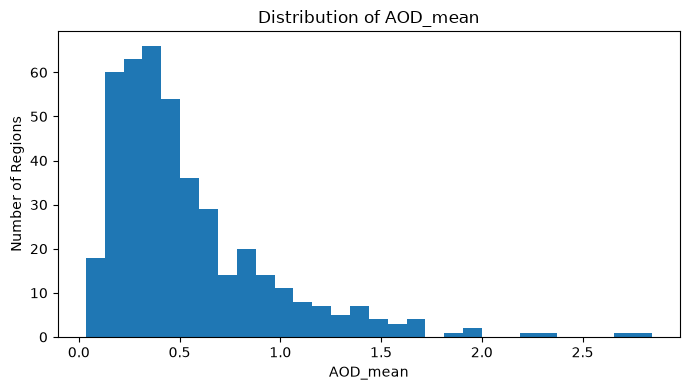

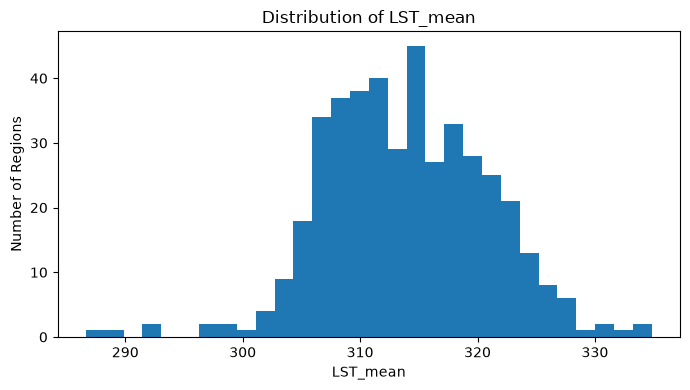

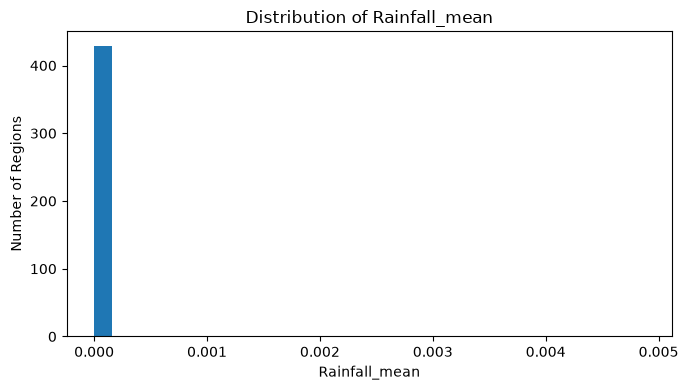

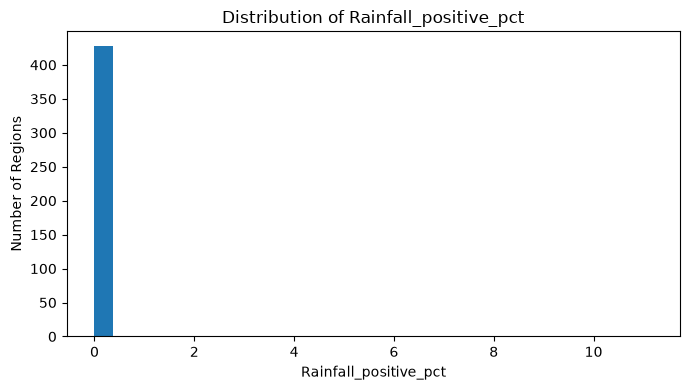

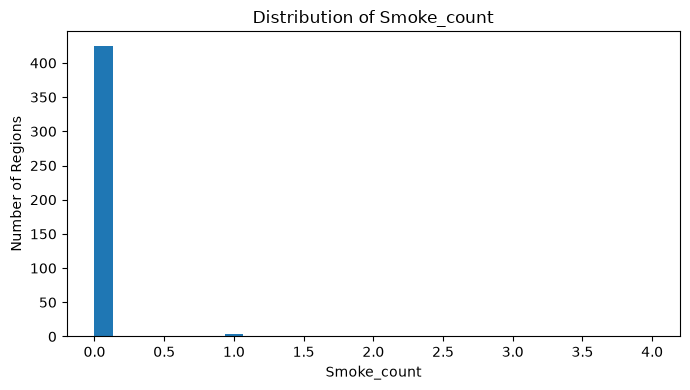

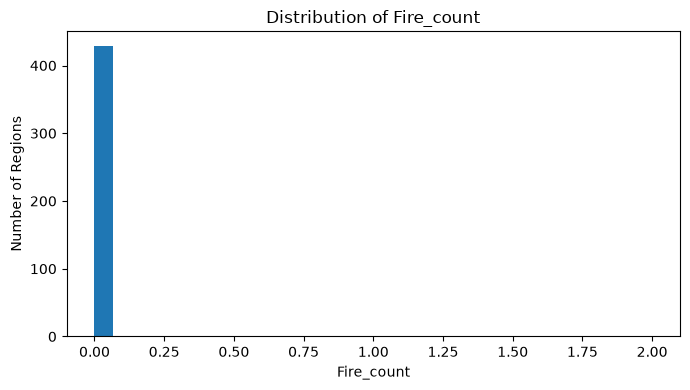

In [22]:
# =====================================================
# FEATURE DISTRIBUTIONS
# =====================================================

import matplotlib.pyplot as plt

for column in cluster_features:
    plt.figure(figsize=(7, 4))
    
    plt.hist(X[column], bins=30)
    
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Regions")
    
    plt.tight_layout()
    plt.show()

In [23]:
# =====================================================
# FEATURE CORRELATION
# =====================================================

correlation_matrix = X.corr()

display(correlation_matrix)

,AOD_mean,LST_mean,Rainfall_mean,Rainfall_positive_pct,Smoke_count,Fire_count
AOD_mean,1.000000,0.329046,0.056981,0.054771,-0.058003,-0.040390
LST_mean,0.329046,1.000000,-0.015829,-0.023957,-0.059079,0.017532
Rainfall_mean,0.056981,-0.015829,1.000000,0.998898,-0.004536,-0.002393
Rainfall_positive_pct,0.054771,-0.023957,0.998898,1.000000,-0.004733,-0.002497
Smoke_count,-0.058003,-0.059079,-0.004536,-0.004733,1.000000,-0.004418
Fire_count,-0.040390,0.017532,-0.002393,-0.002497,-0.004418,1.000000


In [24]:
cluster_features = [
    "AOD_mean",
    "LST_mean"
]

X = final_0530[cluster_features].copy()

print("Final clustering features:", cluster_features)
print("Shape:", X.shape)
display(X.describe())

Final clustering features: ['AOD_mean', 'LST_mean']
Shape: (430, 2)


,AOD_mean,LST_mean
count,430.000000,430.000000
mean,0.543346,313.906692
std,0.412081,6.926630
min,0.035210,286.645050
25%,0.272567,308.946507
50%,0.423867,313.895005
75%,0.674262,318.756012
max,2.843199,334.838600


In [25]:
# =====================================================
# OUTLIER CHECK USING IQR
# =====================================================

for column in ["AOD_mean", "LST_mean"]:

    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X[
        (X[column] < lower_bound) |
        (X[column] > upper_bound)
    ]

    print("=" * 50)
    print(column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of outliers:", len(outliers))

AOD_mean
Q1: 0.2725674325
Q3: 0.6742616
IQR: 0.40169416750000003
Lower bound: -0.32997381875000004
Upper bound: 1.27680285125
Number of outliers: 29
LST_mean
Q1: 308.9465075
Q3: 318.7560125
IQR: 9.809505000000001
Lower bound: 294.23225
Upper bound: 333.47027
Number of outliers: 6


In [26]:
# =====================================================
# STANDARDIZE CLUSTERING FEATURES
# =====================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=cluster_features,
    index=X.index
)

print("Before standardization:")
display(X.describe())

print("\nAfter standardization:")
display(X_scaled.describe())

Before standardization:


,AOD_mean,LST_mean
count,430.000000,430.000000
mean,0.543346,313.906692
std,0.412081,6.926630
min,0.035210,286.645050
25%,0.272567,308.946507
50%,0.423867,313.895005
75%,0.674262,318.756012
max,2.843199,334.838600



After standardization:


,AOD_mean,LST_mean
count,4.300000e+02,4.300000e+02
mean,-1.239319e-16,-1.677211e-15
std,1.001165e+00,1.001165e+00
min,-1.234534e+00,-3.940357e+00
25%,-6.578653e-01,-7.169377e-01
50%,-2.902788e-01,-1.689212e-03
75%,3.180646e-01,7.009136e-01
max,5.587575e+00,3.025467e+00
